# 01 · Effects with a known answer: who benefits from coaching in a simulated care program

A care program for adults with type 2 diabetes offers coaching calls, and it wants to know two things: whether the calls lower members' HbA1c, and for which members they lower it most. HbA1c measures average blood sugar over the past three months, in percent; lowering it is the program's main clinical aim. The program has records of past members, who was called and how their HbA1c changed. What it does not have is a randomized trial. Coaches decided whom to call, and they called the members who looked most in need and most likely to respond.

That makes this a question about effects, not predictions. A model that predicts a member's HbA1c change very accurately can still be wrong about what a call would change, because the members who were called differ from the others in ways that change HbA1c with or without a call. The program's analysts need a different kind of estimate, and a way to tell when to trust it.

This notebook works through the problem on a simulated program, where the answer is known. A simulator can record what would have happened to every member both with and without a call; real data never can. So every estimate below can be scored against each member's true effect. The notebook answers, in order:

1. **What is an effect, and why can it not be read off the data?**
2. **How far off is the plain comparison** of called and uncalled members?
3. **Which estimators recover the average effect,** and does a strong predictor, TabPFN, help as the model inside them?
4. **Which recover each member's effect,** and do any of them shrink the differences between members?
5. **If the program can call only 30% of its members,** whose choice of members captures most of the possible benefit?
6. **What happens as the coaches' choices get more selective,** until the called and uncalled members barely overlap?

Notebook 02 then takes the same estimators to a real observational study.

## What an effect is

Write $Y_i(1)$ for the HbA1c reduction member $i$ would have over six months if called, and $Y_i(0)$ for the reduction without a call. These are the member's two *potential outcomes*. The effect of a call on member $i$ is their difference, $Y_i(1) - Y_i(0)$. Every member has both potential outcomes, but the data show only one of them: $Y_i(1)$ for a member who was called, $Y_i(0)$ for one who was not. The other is missing for everyone, which is why no individual effect can ever be observed, only estimated.

What can be estimated are averages. With $X_i$ the member's covariates, the things the program knew before deciding whether to call, the *conditional average treatment effect* (CATE) is

$$
\tau(x) = \mathbb{E}[Y(1) - Y(0) \mid X = x],
$$

the average effect among members who look like $x$. It is what a decision about one member should rest on. Its average over all members is the *average treatment effect* (ATE), $\mathbb{E}[Y(1) - Y(0)]$; its average over the members who were actually called is the *average treatment effect on the treated* (ATT).

Two conditions make these estimable from observational data, and the simulation below satisfies both by construction:

- **No unmeasured confounding.** Whether a member was called depends only on the covariates the data contain, not on anything else that also affects their HbA1c. Then, among members with the same $x$, the called and uncalled are comparable.
- **Overlap.** Every member had some chance of either arm: the *propensity* $e(x) = P(\text{called} \mid X = x)$ lies strictly between 0 and 1. Without overlap there are members with no comparable people in the other arm.

The first condition can never be checked from the data alone; in real data it is an assumption argued from how decisions were made. The second can be checked, and section 7 shows what happens as it fails.

## 1. Setup

`helper.py` in this folder holds the simulator, the three base models and the plots; the estimators are general and come from `tabicllab.treatment_effects` in the lab's package. This notebook fits TabPFN several dozen times, which is quick on a GPU and slow on a laptop CPU, so it is executed on a GPU pod. With the environment variable `TE_SMOKE=1` it runs on a small table with a light TabPFN instead, to check that every cell works; `TE_MEMBERS` and `TE_FOLDS` set the number of members and of cross-fitting folds for either mode.

In [1]:
import time

import numpy as np
import pandas as pd

import helper
from helper import COVARIATES, base_learners, simulate_care_program
from tabicllab.treatment_effects import (
    aipw_ate,
    cate_scores,
    dr_learner,
    fit_nuisances,
    fold_ids,
    ipw_ate,
    naive_difference,
    overlap_summary,
    s_learner,
    t_learner,
    x_learner,
)

helper.configure_plots(plots=True)
tabpfn_version = helper.init_tabpfn()

N_MEMBERS, N_FOLDS = helper.N_MEMBERS, helper.N_FOLDS
print(f"{N_MEMBERS} members, {N_FOLDS} cross-fitting folds")

TabPFN v3.5 weights, running on NVIDIA A40
2000 members, 5 cross-fitting folds


## 2. The simulated program

The simulator draws 2,000 members. Each has eight covariates the program knows before deciding: age, baseline HbA1c, body-mass index, years since diagnosis, whether they are on insulin, how many days they used the program's app in the last month, sex, and LDL cholesterol. The last two play no part in anything; real tables carry columns like that.

Three rules, written out in `simulate_care_program`'s docstring, then decide the rest:

- **Without a call,** a member's HbA1c falls more when it starts high, partly because a high reading is often a bad stretch that passes, and falls more for members who are active in the app. Members on insulin, with a higher body-mass index or older improve a little less.
- **A call** adds a reduction of its own, the member's true effect: 0.2 points for everyone, more when baseline HbA1c is above 7.5 and when the member is engaged with the app, and less for members on insulin.
- **Coaches call** members with high HbA1c and high app use more often, and older members slightly less often. A single number, the *selection strength*, sets how strongly they choose; the default is 1, and 0 would be a randomized trial.

The table shows the observed columns and, at the right, the columns only a simulator has: both potential outcomes, their expected values, the true effect and the true probability of a call.

In [2]:
frame = simulate_care_program(N_MEMBERS, selection=1.0, seed=0)
frame.head()

,age,baseline_hba1c,bmi,years_since_diagnosis,on_insulin,app_days_last_month,sex,ldl,coached,hba1c_reduction,y0,y1,expected_y0,expected_y1,true_effect,true_propensity
member,,,,,,,,,,,,,,,,
M00001,58.7,9.84,26.8,5.7,1,18,0,132.0,1,1.239,0.353,1.239,0.799,1.685,0.886,0.824
M00002,42.1,6.74,38.1,0.4,0,7,0,109.0,0,-0.068,-0.068,0.149,-0.640,-0.424,0.216,0.156
M00003,31.8,7.21,28.9,6.2,0,9,0,117.0,0,0.567,0.567,0.797,-0.185,0.045,0.230,0.297
M00004,30.7,7.18,36.6,1.7,0,10,1,103.0,0,-0.674,-0.674,-0.435,-0.310,-0.070,0.240,0.322
M00005,66.6,8.94,41.5,5.3,0,10,1,62.0,1,1.568,0.896,1.568,0.028,0.700,0.672,0.437


## 3. The plain comparison

The data an analyst would actually have are the covariates, whether the member was called, and the reduction they had. The simplest estimate of the effect is the difference between the average reduction of called and uncalled members.

In [3]:
X = frame[COVARIATES].to_numpy(dtype=float)
t = frame["coached"].to_numpy()
y = frame["hba1c_reduction"].to_numpy()
true_ate = frame["true_effect"].mean()
true_att = frame.loc[frame["coached"] == 1, "true_effect"].mean()

naive = naive_difference(t, y)
print(f"{t.sum()} of {len(t)} members were called")
print(f"plain comparison: {naive.estimate:.3f} (95% interval {naive.interval()[0]:.3f} to {naive.interval()[1]:.3f})")
print(f"true average effect, all members (ATE): {true_ate:.3f}")
print(f"true average effect, called members (ATT): {true_att:.3f}")

816 of 2000 members were called
plain comparison: 1.004 (95% interval 0.936 to 1.071)
true average effect, all members (ATE): 0.465
true average effect, called members (ATT): 0.590


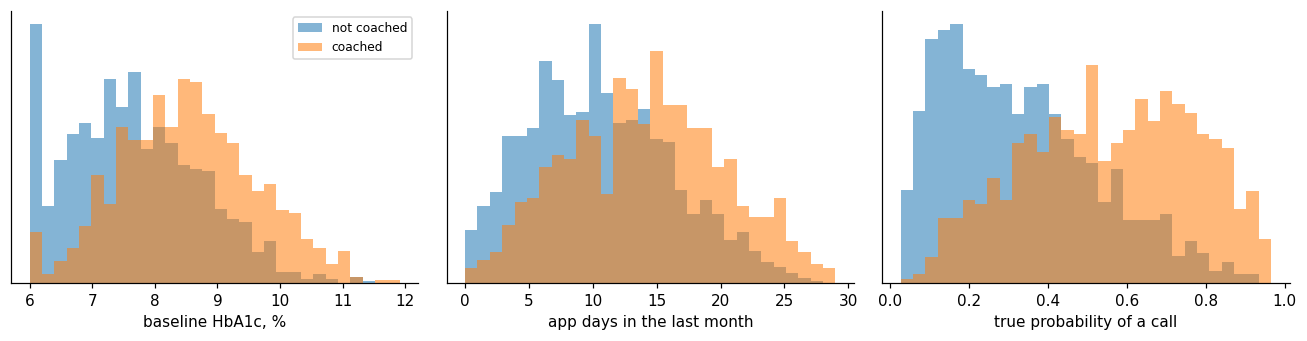

In [4]:
helper.plot_who_gets_coached(frame)

The plain comparison says a call lowers HbA1c by 1.00 point. The true average effect is 0.465, less than half of that, and the comparison's 95% interval, 0.94 to 1.07, does not come near it. The interval is narrow because 2,000 members make the estimate precise; more members would only narrow it further around the same wrong value.

The histograms show why it is wrong. Called members start with a higher HbA1c and use the app more, and in this program both of those make HbA1c fall with or without a call. Part of the called members' larger reduction is the reduction they would have had anyway, and the plain comparison credits it to the call. That is confounding: a common cause of who is treated and of the outcome.

Even the right answer depends on the question asked. The average effect over all members is 0.465, but over the members who were actually called it is 0.590, because the coaches favour members with a high HbA1c and high engagement, who also benefit more. A program asking whether its calls worked for the people it called wants the second number; one asking what calling everyone would do wants the first. The rest of the notebook targets the first, and each member's own effect.

## 4. The two models every estimator needs

Every estimator below rests on two prediction problems, called *nuisances* because they are not the goal but are needed to reach it:

- the **outcome models**, $\mu_0(x) = \mathbb{E}[Y \mid X = x, \text{not called}]$ and $\mu_1(x) = \mathbb{E}[Y \mid X = x, \text{called}]$, the expected reduction without and with a call for members who look like $x$;
- the **propensity model**, $e(x)$, the probability of a call.

Under the two conditions above, $\tau(x) = \mu_1(x) - \mu_0(x)$, so good outcome models give good effects; the propensity is what lets an estimator correct for who was called. Here is where a strong tabular predictor could help, and it is the first thing to measure. Each of three base models fits all three nuisances:

- **linear**: linear and logistic regression without interactions, what an analyst would fit first;
- **gradient boosting**: XGBoost tuned by a cross-validated grid search, the strong conventional choice;
- **TabPFN**: untuned.

Every prediction is *cross-fitted*: the members are split into five folds, and each fold is predicted by models fitted on the other four, so no member's prediction comes from a model that saw them. Because the simulator knows the true $\mu_0$, $\mu_1$ and $e$, each fit can be scored directly: the root mean squared error against the truth, for the outcome models in reduction units and for the propensity in probability units.

In [5]:
learners = base_learners(seed=0)
folds = fold_ids(t, n_folds=N_FOLDS, seed=0)

nuisances, seconds = {}, {}
for name, (regressor, classifier) in learners.items():
    start = time.perf_counter()
    nuisances[name] = fit_nuisances(X, t, y, regressor, classifier, folds)
    seconds[name] = time.perf_counter() - start

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

pd.DataFrame({
    name: {
        "outcome without call, RMSE": rmse(nu.mu0, frame["expected_y0"]),
        "outcome with call, RMSE": rmse(nu.mu1, frame["expected_y1"]),
        "propensity, RMSE": rmse(nu.e_raw, frame["true_propensity"]),
        "seconds": seconds[name],
    }
    for name, nu in nuisances.items()
}).T

,"outcome without call, RMSE","outcome with call, RMSE","propensity, RMSE",seconds
linear,0.059,0.130,0.033,0.049
gradient boosting,0.159,0.179,0.087,15.490
TabPFN,0.071,0.080,0.041,14.009


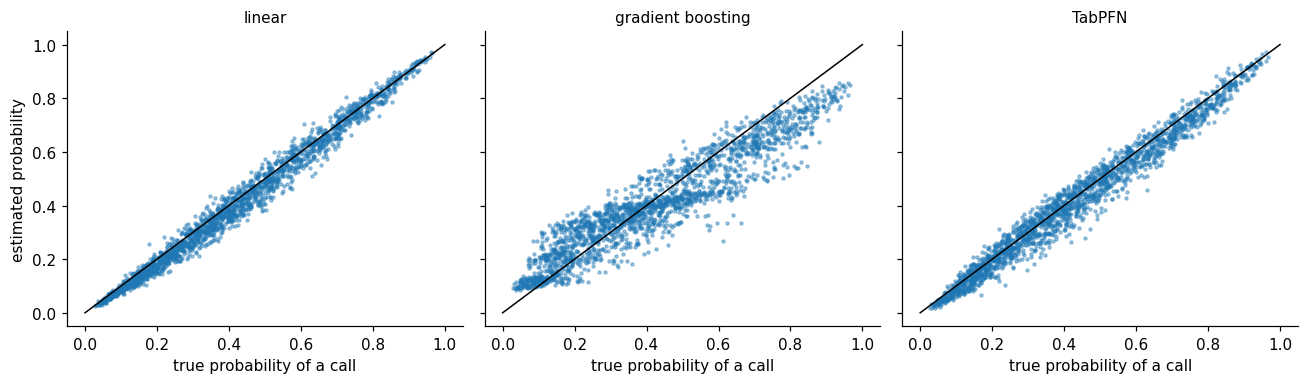

In [6]:
helper.plot_propensities(frame, {name: nu.e_raw for name, nu in nuisances.items()})

Each base model is best somewhere, and the simulator's equations say why:

- **The propensity** is exactly a logistic function of three covariates, so logistic regression is the right model, and it is the most accurate (RMSE 0.033 in probability units). TabPFN comes close (0.041). Tuned gradient boosting is more than twice as far off (0.087); its panel shows the step-shaped fit that trees give a smooth function, too high for members unlikely to be called and too low for members likely to be.
- **The outcome without a call** is nearly linear by construction, and the linear model is again the most accurate (0.059), with TabPFN close behind (0.071).
- **The outcome with a call** adds the effect's kink at HbA1c 7.5 and its S-shaped rise with app use. The linear model cannot follow that shape (0.130), and TabPFN is the most accurate (0.080).

So untuned TabPFN comes within a small margin of the correctly specified model where one exists, and is the most accurate where none does, while gradient boosting, even tuned, is the least accurate of the three on all three problems at this sample size. This simulator is kind to the linear model, since two of the three nuisances are linear or nearly so; coaches who decided by thresholds or by combinations of covariates would make it harder. The times are for an NVIDIA A40 GPU, with the grid search parallelized over the pod's CPU cores.

## 5. The average effect

Four estimators of the average effect, each built on each base model:

- **plain comparison**, from section 3, for reference;
- **regression adjustment**: the average over all members of $\hat\mu_1(x) - \hat\mu_0(x)$. It relies entirely on the outcome models;
- **inverse propensity weighting (IPW)**: each called member is weighted by $1 / \hat e(x)$ and each uncalled member by $1 / (1 - \hat e(x))$, so that both weighted groups resemble the whole membership, and the weighted averages are compared. It relies entirely on the propensity;
- **augmented IPW (AIPW)**: regression adjustment plus a weighted average of each member's residual in their own arm,

$$
\hat\tau_{\mathrm{AIPW}} = \frac{1}{n} \sum_{i=1}^{n} \left[ \hat\mu_1(x_i) - \hat\mu_0(x_i) + \frac{t_i \left(y_i - \hat\mu_1(x_i)\right)}{\hat e(x_i)} - \frac{(1 - t_i) \left(y_i - \hat\mu_0(x_i)\right)}{1 - \hat e(x_i)} \right],
$$

where $n$ is the number of members, $t_i$ is 1 for a called member and 0 otherwise, and $y_i$ is the observed reduction. The correction term fixes what the outcome models got wrong, using the propensity. AIPW is *doubly robust*: it is consistent when either the outcome models or the propensity are correct. With cross-fitted nuisances, it is the double machine learning estimator of the average effect.

Propensities are clipped to the range 0.01 to 0.99 before weighting, so that no single member's weight can exceed 100. The table gives each estimate with its standard error and whether its 95% interval contains the true average effect.

In [7]:
rows = []
naive_row = {"learner": "none", "method": "plain comparison", "estimate": naive.estimate, "se": naive.se}
rows.append(naive_row)
for name, nu in nuisances.items():
    adjusted = t_learner(nu).mean()
    rows.append({"learner": name, "method": "regression adjustment", "estimate": adjusted, "se": np.nan})
    for method, estimate in [("IPW", ipw_ate(t, y, nu.e)), ("AIPW", aipw_ate(t, y, nu))]:
        rows.append({"learner": name, "method": method, "estimate": estimate.estimate, "se": estimate.se})

average = pd.DataFrame(rows)
average["error"] = average["estimate"] - true_ate
low, high = average["estimate"] - 1.96 * average["se"], average["estimate"] + 1.96 * average["se"]
average["interval covers truth"] = np.where(average["se"].isna(), "", np.where((low <= true_ate) & (true_ate <= high), "yes", "no"))
print(f"true average effect: {true_ate:.3f}")
average.set_index(["learner", "method"])

true average effect: 0.465


estimate     se  error interval covers truth
learner           method                                                             
none              plain comparison          1.004  0.034  0.539                    no
linear            regression adjustment     0.454    NaN -0.011                      
                  IPW                       0.496  0.049  0.031                   yes
                  AIPW                      0.472  0.030  0.007                   yes
gradient boosting regression adjustment     0.551    NaN  0.087                      
                  IPW                       0.650  0.041  0.186                    no
                  AIPW                      0.505  0.026  0.040                   yes
TabPFN            regression adjustment     0.484    NaN  0.019                      
                  IPW                       0.511  0.050  0.046                   yes
                  AIPW                      0.483  0.030  0.018                   yes

**A cross-check with DoubleML.** The DoubleML package implements the same doubly robust estimator, with its own fold split and code. Given the same base models it should agree with the AIPW rows above to within the noise of a different split.

In [8]:
import doubleml as dml

data = dml.DoubleMLData(frame[COVARIATES + ["coached", "hba1c_reduction"]], "hba1c_reduction", "coached", COVARIATES)
crosscheck = {}
for name, (regressor, classifier) in learners.items():
    model = dml.DoubleMLIRM(data, regressor(), classifier(), n_folds=N_FOLDS, trimming_threshold=0.01)
    model.fit()
    crosscheck[name] = {"DoubleML estimate": model.coef[0], "DoubleML se": model.se[0],
                        "our AIPW": aipw_ate(t, y, nuisances[name]).estimate}
pd.DataFrame(crosscheck).T

,DoubleML estimate,DoubleML se,our AIPW
linear,0.478,0.030,0.472
gradient boosting,0.478,0.032,0.505
TabPFN,0.473,0.033,0.483


The errors are best read against the standard errors, which are about 0.03 for AIPW:

- **AIPW lands within about one standard error of the truth with every base model:** 0.472 with linear models, 0.483 with TabPFN and 0.505 with gradient boosting, against a true 0.465, and all three intervals contain it. The differences between the three are smaller than their standard errors, so this run cannot rank the base models for the average effect.
- **Estimators that rest on one nuisance inherit its errors.** IPW with gradient boosting's propensities is off by 0.186, and its interval misses the truth: the flattened propensities give the wrong weights. Regression adjustment with gradient boosting's outcome models is off by 0.087. With TabPFN, both single-nuisance estimators stay within 0.05 of the truth, and with linear models within 0.04.
- **DoubleML agrees.** With its own fold split it gives 0.478, 0.478 and 0.473 for the three base models, within one standard error of the hand-written AIPW in each case, which checks the implementation.

This is what double robustness buys: gradient boosting's poor propensities are largely corrected by its outcome models, so the choice of base model matters much less for AIPW than for IPW or regression adjustment alone.

## 6. Each member's effect

The average says whether calls help; a decision about one member needs that member's effect. Four estimators of $\tau(x)$, the *meta-learners*, each again built on each base model:

- **S-learner**: one outcome model with the call as one more column; the effect is its prediction with the column set to 1 minus with it set to 0;
- **T-learner**: the two outcome models of section 4, one per arm; the effect is $\hat\mu_1(x) - \hat\mu_0(x)$;
- **X-learner**: impute each member's effect from the other arm's model, $y - \hat\mu_0(x)$ for a called member and $\hat\mu_1(x) - y$ for an uncalled one; fit a model to the imputed effects in each arm; blend the two by the propensity;
- **DR-learner**: compute the bracketed term of the AIPW formula for every member, a noisy but unbiased signal of their effect called the *pseudo-outcome*, and fit a model to it.

Each estimate is scored against the true effects:

- **PEHE**: the root mean squared error of the estimated effects (the name stands for precision in estimating heterogeneous effects);
- **correlation**: how well the estimates order the members;
- **slope**: the slope of the estimates regressed on the true effects. At 1, differences between members are reproduced at full size; below 1, they are shrunk towards a common value; at 0, everyone gets the same effect.

For scale, the true effects have a standard deviation of 0.267 across members, so an estimator that gave every member the true average would have a PEHE of that size.

In [9]:
tau = frame["true_effect"].to_numpy()
estimates = {}
for name, (regressor, classifier) in learners.items():
    nu = nuisances[name]
    estimates[(name, "S-learner")] = s_learner(X, t, y, regressor, folds)
    estimates[(name, "T-learner")] = t_learner(nu)
    estimates[(name, "X-learner")] = x_learner(X, t, y, nu, regressor, folds)
    estimates[(name, "DR-learner")] = dr_learner(X, t, y, nu, regressor, folds)

individual = pd.DataFrame(
    {key: cate_scores(value, tau, budget=0.3) for key, value in estimates.items()}
).T.rename_axis(["learner", "method"])
print(f"true effects: mean {tau.mean():.3f}, standard deviation {tau.std():.3f}")
individual[["pehe", "correlation", "slope", "ate_error"]]

true effects: mean 0.465, standard deviation 0.267


pehe  correlation      slope  ate_error
learner           method                                              
linear            S-learner   0.269       -0.011 -2.671e-04      0.038
                  T-learner   0.121        0.931  1.114e+00     -0.011
                  X-learner   0.115        0.937  1.118e+00     -0.011
                  DR-learner  0.118        0.923  1.056e+00      0.006
gradient boosting S-learner   0.145        0.870  6.032e-01      0.039
                  T-learner   0.191        0.858  1.061e+00      0.087
                  X-learner   0.111        0.943  7.523e-01      0.054
                  DR-learner  0.139        0.866  7.221e-01      0.039
TabPFN            S-learner   0.080        0.976  7.776e-01      0.026
                  T-learner   0.082        0.966  1.082e+00      0.019
                  X-learner   0.062        0.974  9.768e-01      0.011
                  DR-learner  0.068        0.971  9.893e-01      0.019

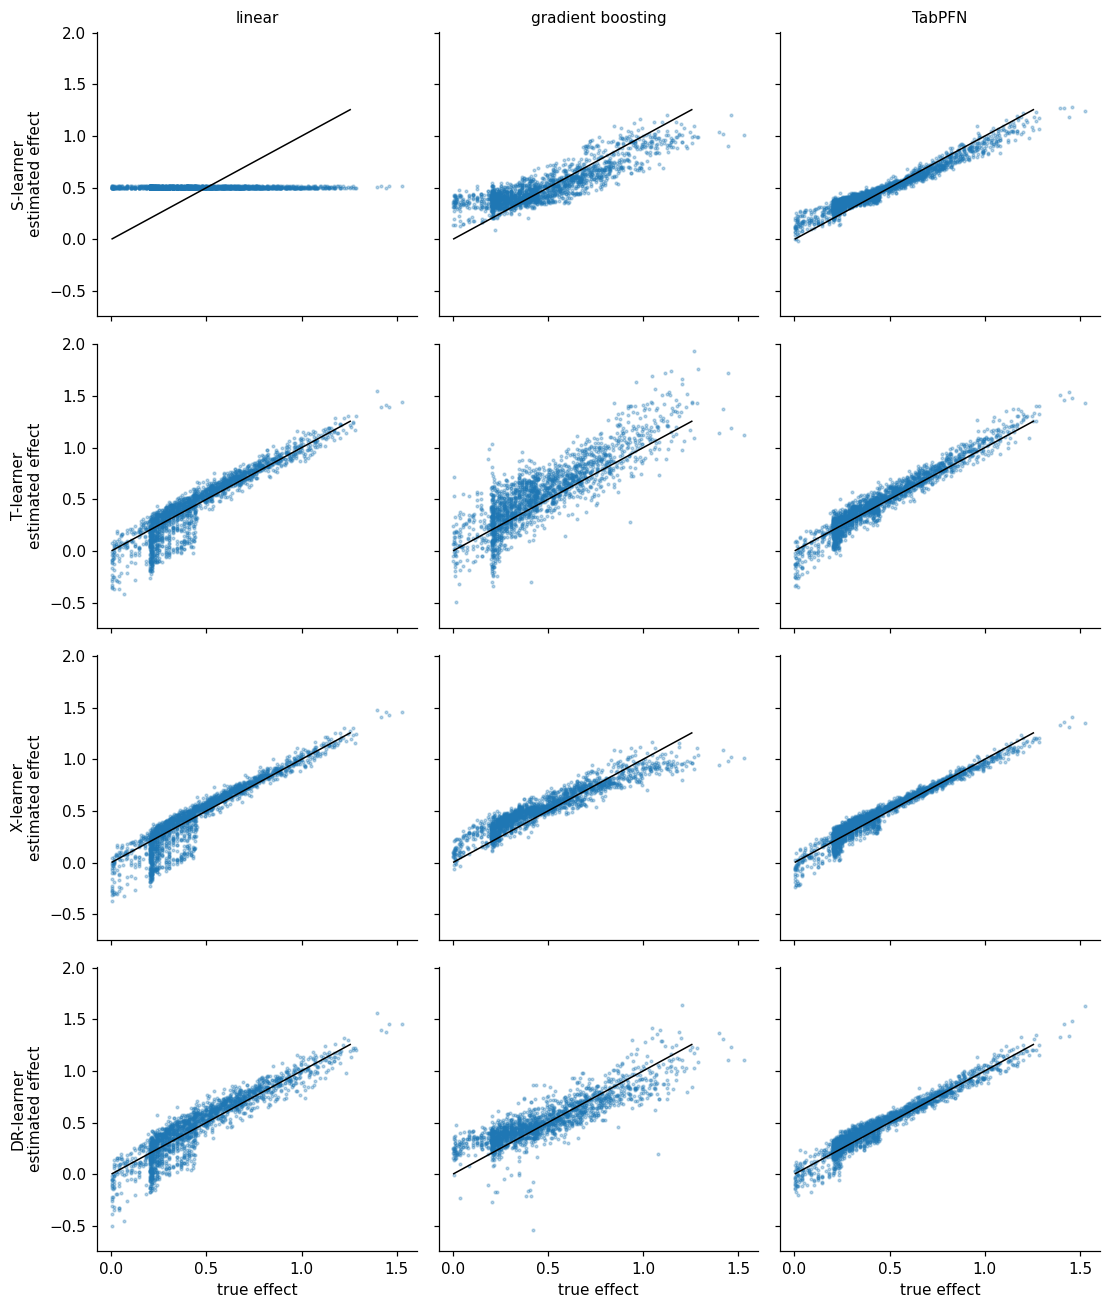

In [10]:
helper.plot_effect_estimates(frame, estimates, list(learners), ["S-learner", "T-learner", "X-learner", "DR-learner"])

Three findings, each visible in the scatter plots:

- **TabPFN gives the most accurate individual effects with every one of the four meta-learners.** Its best, the X-learner, has a PEHE of 0.062, against 0.111 for the best gradient-boosting learner and 0.115 for the best linear one, about half the error of either. Its estimates follow both the kink at HbA1c 7.5 and the flat stretch below it; at the lowest true effects, where the linear learners leave a vertical streak of members they cannot tell apart, TabPFN's points stay on the diagonal.
- **The S-learner shrinks, and how much depends on the base model.** The linear S-learner gives every member the same effect, about 0.50, because a linear model without interaction terms cannot let the call's effect depend on anything (slope 0). The gradient-boosting S-learner reproduces differences between members at 60% of their true size, and TabPFN's at 78%: it orders members almost perfectly (correlation 0.976) but compresses them towards the average. So TabPFN does shrink effects when the call is one column among nine, less than gradient boosting does. The X- and DR-learners, which model the effect directly, remove the shrinkage: with TabPFN their slopes are 0.98 and 0.99.
- **The T-learner is only as good as two separate fits.** With gradient boosting it is the least accurate learner in its row (PEHE 0.191), because the difference of two independently fitted boosted models carries both models' errors. The X-learner, built on the same two models, cuts that error to 0.111.

## 7. Calling the members who benefit most

Suppose the program can call only 30% of its members. Each estimator ranks the members by their estimated effect and calls the top 30%. The score is the gain this targeting achieves over calling a random 30%, as a share of the gain of the best possible 30%: 0 is no better than chance, 1 is as good as knowing every member's true effect. The table also gives the average true effect of the members each estimator would call.

In [11]:
k = int(round(0.3 * len(tau)))
called = {key: tau[np.argsort(-value, kind="stable")[:k]].mean() for key, value in estimates.items()}
targeting = individual[["targeting"]].assign(**{"mean true effect of those called": pd.Series(called)})
print(f"mean true effect: random 30% {tau.mean():.3f}, best possible 30% {np.sort(tau)[::-1][:k].mean():.3f}")
targeting.unstack("method")["targeting"].round(2)

mean true effect: random 30% 0.465, best possible 30% 0.804


method,DR-learner,S-learner,T-learner,X-learner
learner,,,,
TabPFN,1.00,0.99,0.98,1.00
gradient boosting,0.93,0.93,0.88,0.96
linear,0.97,0.00,0.99,0.99


Targeting is a more forgiving task than estimating effects. Every estimator except the linear S-learner captures at least 88% of the attainable gain, and eight of the eleven capture 95% or more. Ranking needs only the order of members, not the size of their effects, so TabPFN's S-learner, which shrinks effects by a fifth, still captures 99%. The linear S-learner captures nothing: it gives everyone the same estimate, so its choice is as good as a random one. Gradient boosting's T-learner, the noisiest estimator, captures 88%.

Which measure to trust therefore depends on the decision. Deciding whom to call first needs the order of members, which almost every estimator gets right here. Deciding whether a call is worth its cost for a particular member needs the size of that member's effect, and there PEHE and the slope separate the estimators clearly.

## 8. More selective coaches

The default selection strength gives fair overlap: few members had almost no chance of either arm. As coaches choose more strongly, the called and uncalled members grow apart, and some members end up with no comparable people in the other arm. The sweep below redraws the program at six selection strengths, from a randomized trial (0) to strongly selective (3), with the same members' covariates and outcomes, and records the error of the three average-effect estimators for each base model, together with how many members have an extreme true propensity (below 0.05 or above 0.95) and the effective number of members left in each weighted arm.

In [12]:
strengths = [0.0, 1.0, 2.0] if helper.SMOKE else [0.0, 0.5, 1.0, 1.5, 2.0, 3.0]
sweep_rows, overlap_rows = [], []
for strength in strengths:
    drawn = simulate_care_program(N_MEMBERS, selection=strength, seed=0)
    Xs, ts, ys = drawn[COVARIATES].to_numpy(dtype=float), drawn["coached"].to_numpy(), drawn["hba1c_reduction"].to_numpy()
    truth = drawn["true_effect"].mean()
    overlap_rows.append({"selection": strength, **overlap_summary(ts, drawn["true_propensity"])})
    fs = fold_ids(ts, n_folds=N_FOLDS, seed=0)
    for name, (regressor, classifier) in learners.items():
        nu = fit_nuisances(Xs, ts, ys, regressor, classifier, fs)
        for method, estimate in [("naive", naive_difference(ts, ys)), ("IPW", ipw_ate(ts, ys, nu.e)), ("AIPW", aipw_ate(ts, ys, nu))]:
            sweep_rows.append({"selection": strength, "learner": name, "method": method,
                               "error": estimate.estimate - truth, "se": estimate.se})

sweep = pd.DataFrame(sweep_rows)
overlap = pd.DataFrame(overlap_rows).set_index("selection")
overlap[["share_extreme", "effective_n_treated", "effective_n_control", "n_treated", "n_control"]]

,share_extreme,effective_n_treated,effective_n_control,n_treated,n_control
selection,,,,,
0.0,0.000,786.000,1214.000,786,1214
0.5,0.000,732.348,1105.482,820,1180
1.0,0.011,548.680,870.497,816,1184
1.5,0.104,414.363,389.130,848,1152
2.0,0.231,260.090,284.119,869,1131
3.0,0.425,181.924,85.688,906,1094


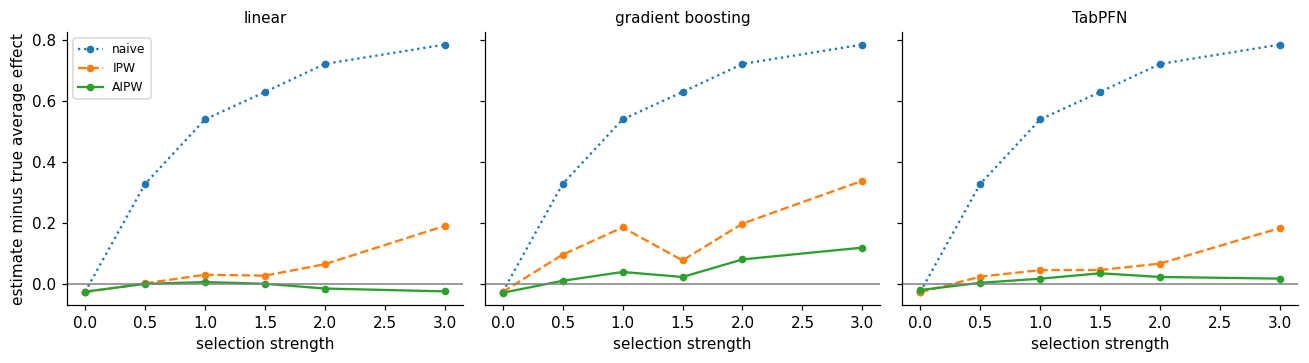

learner   TabPFN               gradient boosting               linear              
method      AIPW    IPW  naive              AIPW    IPW  naive   AIPW    IPW  naive
selection                                                                          
0.0       -0.019 -0.027 -0.025            -0.028 -0.026 -0.025 -0.025 -0.026 -0.025
0.5        0.004  0.025  0.328             0.011  0.096  0.328  0.001  0.003  0.328
1.0        0.018  0.046  0.539             0.040  0.186  0.539  0.007  0.031  0.539
1.5        0.036  0.046  0.629             0.023  0.078  0.629  0.001  0.028  0.629
2.0        0.023  0.067  0.720             0.081  0.198  0.720 -0.014  0.065  0.720
3.0        0.018  0.184  0.784             0.119  0.338  0.784 -0.024  0.191  0.784

In [13]:
helper.plot_selection_sweep(sweep)
sweep.pivot_table(index="selection", columns=["learner", "method"], values="error").round(3)

As selection strengthens, the plain comparison's error grows from almost nothing in the randomized trial to 0.78 at strength 3, larger than the effect itself. The weighted estimators hold up for a while and then part ways:

- **IPW degrades with every base model once overlap goes,** reaching errors of 0.18 to 0.34 at strength 3, even with logistic regression, the correct propensity model. At that strength 42% of members have a true propensity below 0.05 or above 0.95, their weights hit the clip at 100, and the uncalled arm is worth only 86 effective members.
- **AIPW stays within 0.04 of the truth at every strength with linear models and with TabPFN.** Where overlap fails, it leans on the outcome models to supply comparisons the data cannot make, and both of these base models predict outcomes well.
- **AIPW with gradient boosting drifts to an error of 0.12 at strength 3,** because its outcome models are the least accurate and its propensities the most flattened, so neither part of the doubly robust estimate is reliable where the other is needed.

At strength 0 every estimate sits 0.02 to 0.03 below the truth: that is the sampling noise of one randomized trial of 2,000 members, not a bias. Double robustness protects against one wrong model, not against missing comparisons. Where members have no comparable people in the other arm, any estimate is only as good as the outcome model's extrapolation, which is why an overlap check like the table above belongs before any estimate.

## What this leaves open

- **One table, one fold split.** Every number above comes from one simulated program, and the [results page](docs/results/01-effects-with-a-known-answer.md) repeats the analysis over ten draws. The repetition confirms TabPFN's lead on individual effects, but this draw turns out to be its most favourable of the ten: over all ten, its X-learner's PEHE averages 0.084 against about 0.120 for both references, about 30% lower rather than half. The average-effect estimates stay within each other's standard errors.
- **A simulator that suits the linear model.** The propensity is exactly logistic and the outcome without a call nearly linear, so linear models do well here by construction. The results page adds a scenario in which coaches decide by thresholds and combinations of covariates and outcomes depend on interactions. There TabPFN still gives the most accurate individual effects, and AIPW built on linear models, with both of its models wrong, is biased by a quarter of the effect and covers the truth in only 3 draws of 10.
- **No unmeasured confounding, by construction.** The simulator guarantees that every reason for a call is in the data. Real data never comes with that guarantee, and the next notebook asks how much an estimate could move under a confounder nobody measured.
- **Uncertainty for each member's effect.** The meta-learners give point estimates only. TabPFN's predictive distributions suggest a route to an interval for each member's effect; whether such intervals are honest is still to be measured.
- **Real data.** Notebook 02 takes the same estimators to a real observational study, where no individual effect is known but a published estimate of the average is.